# Exploración inicial del dataset CAMELS-COL

**Objetivo:** entender *qué datos hay* en el dataset, todavía sin analizarlos a fondo.

**Datos:** CAMELS-COL versión 3, públicos en Zenodo (DOI [10.5281/zenodo.18794895](https://doi.org/10.5281/zenodo.18794895)).
No se incluyen en el repositorio por su tamaño. Para descargarlos, ejecutar desde la raíz del repositorio
`python descargar_datos.py`, que los deja en la carpeta `Camels col/`.

**Cómo usarlo:** ejecutar las celdas en orden, de arriba hacia abajo (`Shift + Enter` en cada una, o *Run → Run All Cells*),
desde la raíz del repositorio. Las tablas resultantes se guardan en la carpeta `salidas/`.

## 0. Librerías y rutas

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 50)

BASE = Path("Camels col")
SERIES_DIR = BASE / "04_CAMELS_COL_Hydrometeorological_data" / "3_Hydrometeorological_data"
SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)

assert BASE.exists(), "No se encuentra la carpeta 'Camels col'. Descargue los datos con: python descargar_datos.py"
print("Rutas OK")

Rutas OK


## 1. Inventario de archivos
Qué hay en cada carpeta y de qué tipo son los archivos.

In [2]:
inventario = []
for item in sorted(BASE.iterdir()):
    if item.is_dir():
        archivos = [f for f in item.rglob("*") if f.is_file()]
        tipos = pd.Series([f.suffix.lower() for f in archivos]).value_counts().to_dict()
        inventario.append({"nombre": item.name, "tipo": "carpeta", "n_archivos": len(archivos), "extensiones": tipos})
    else:
        inventario.append({"nombre": item.name, "tipo": "archivo", "n_archivos": 1, "extensiones": {item.suffix: 1}})

pd.DataFrame(inventario)

,nombre,tipo,n_archivos,extensiones
0,00_CAMELS-COL Description (1).docx,archivo,1,{'.docx': 1}
1,01_CAMELS_COL_Attributes,carpeta,2,"{'.xlsx': 1, '.txt': 1}"
2,02_CAMELS_COL_Catchment_information.csv,archivo,1,{'.csv': 1}
3,03_CAMELS_COL_Basin_boundary,carpeta,14,"{'.cpg': 2, '.dbf': 2, '.prj': 2, '.qix': 2, '..."
4,04_CAMELS_COL_Hydrometeorological_data,carpeta,346,{'.txt': 346}
5,05_CAMELS_COL_Geologic_characteristics.csv,archivo,1,{'.csv': 1}
6,06_CAMELS_COL_Land_cover_characteristics.csv,archivo,1,{'.csv': 1}
7,07_CAMELS_COL_Soil_characteristics.csv,archivo,1,{'.csv': 1}
8,08_CAMELS_COL_Climatic_indices.csv,archivo,1,{'.csv': 1}
9,09_CAMELS_COL_Hydrological_signatures.csv,archivo,1,{'.csv': 1}


## 2. Tablas de atributos (una fila por cuenca)

Cada archivo tiene su propio formato, así que la función `cargar_tabla` lo normaliza:
- separador `;` en casi todas, pero `,` en el archivo 09
- el archivo 02 está en encoding Latin-1 (por las tildes)
- algunas columnas traen espacios al final del nombre
- el archivo 11 trae miles de filas vacías y el `gauge_id` como decimal (`11017010.00`)

In [3]:
TABLAS = {
    "informacion":  ("02_CAMELS_COL_Catchment_information.csv", ";", "latin-1"),
    "geologia":     ("05_CAMELS_COL_Geologic_characteristics.csv", ";", "utf-8"),
    "cobertura":    ("06_CAMELS_COL_Land_cover_characteristics.csv", ";", "utf-8"),
    "suelos":       ("07_CAMELS_COL_Soil_characteristics.csv", ";", "utf-8"),
    "clima":        ("08_CAMELS_COL_Climatic_indices.csv", ";", "utf-8"),
    "firmas_hidro": ("09_CAMELS_COL_Hydrological_signatures.csv", ",", "utf-8"),
    "fisiografia":  ("10_CAMELS_COL_Physiograpic_characteristics.csv", ";", "utf-8"),
    "uso_suelo":    ("11_CAMELS_COL_Land_use_capability.csv", ";", "utf-8"),
}


def cargar_tabla(archivo, sep, encoding):
    df = pd.read_csv(BASE / archivo, sep=sep, encoding=encoding)
    df.columns = df.columns.str.strip()
    df = df.dropna(how="all")
    df["gauge_id"] = df["gauge_id"].astype(int)
    return df


tablas = {nombre: cargar_tabla(*params) for nombre, params in TABLAS.items()}

pd.DataFrame([
    {
        "tabla": nombre,
        "filas": df.shape[0],
        "columnas": df.shape[1] - 1,
        "gauge_id_unicos": df["gauge_id"].nunique(),
        "valores_faltantes": int(df.isna().sum().sum()),
        "variables": ", ".join(df.columns[1:]),
    }
    for nombre, df in tablas.items()
])

,tabla,filas,columnas,gauge_id_unicos,valores_faltantes,variables
0,informacion,346,8,346,0,"gauge_department, gauge_lat, gauge_lon, gauge_..."
1,geologia,346,7,346,0,"unconso_depo_perc, hypabyssal_rock_perc, metam..."
2,cobertura,346,6,346,0,"forest_perc, nat_non_forest_form_perc, agricul..."
3,suelos,346,17,346,0,"inceptisols_perc, entisols_perc, andisols_perc..."
4,clima,346,5,346,0,"aridity, high_prec_freq, high_prec_dur, low_pr..."
5,firmas_hidro,346,11,346,0,"q_mean, runoff_ratio, stream_elas, slope_fdc, ..."
6,fisiografia,346,15,346,0,"area, perimeter, gravelius_index, factor_form,..."
7,uso_suelo,346,10,346,0,"class_1, class_2, class_3, class_4, class_5, c..."


### 2a. Información de las estaciones
Ojo: `gauge_lat` y `gauge_lon` **no están en grados**, están en metros (proyección World Mercator).
`gauge_missing` es el % de días sin dato en la serie de esa estación.

In [4]:
info = tablas["informacion"]
info["gauge_star"] = pd.to_datetime(info["gauge_star"], format="%d/%m/%Y")
info["gauge_end"] = pd.to_datetime(info["gauge_end"], format="%d/%m/%Y")
info.head()

,gauge_id,gauge_department,gauge_lat,gauge_lon,gauge_elev,gauge_star,gauge_end,gauge_n,gauge_missing
0,11017010,Choco,606212.61,-8520155.73,78,1981-05-19,2022-12-31,14444,4.986
1,11027010,Choco,648220.64,-8480408.48,1499,1981-01-01,2001-09-21,7212,4.717
2,11027030,Choco,649335.35,-8477208.05,1568,1981-01-01,2022-12-31,14906,2.829
3,11035020,Choco,623335.42,-8542919.18,45,1981-01-01,2004-07-16,7559,12.084
4,11037020,Choco,595194.32,-8528547.98,71,1981-01-01,2022-12-31,14618,4.707


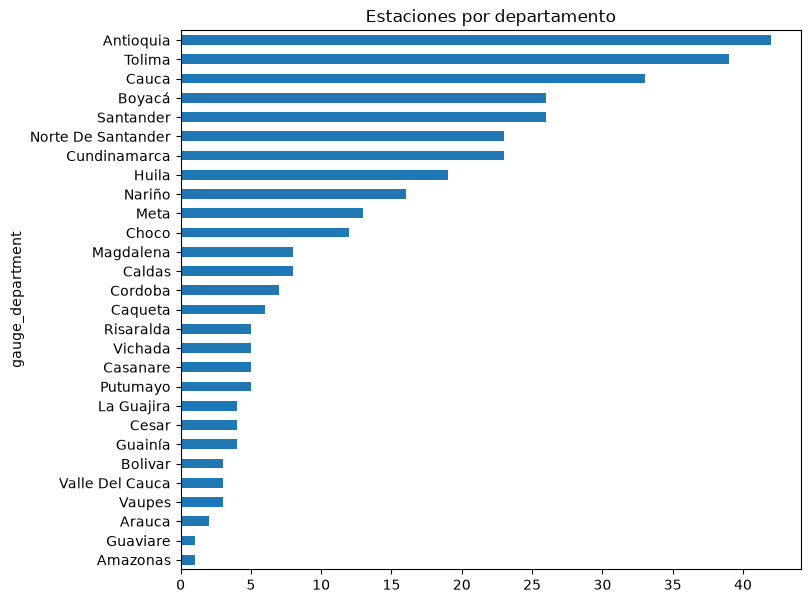

In [5]:
info["gauge_department"].value_counts().plot.barh(figsize=(8, 7), title="Estaciones por departamento")
plt.gca().invert_yaxis()
plt.show()

### 2b. Estadística descriptiva
Fijate en el rango (min–max) de cada variable: hay escalas muy distintas entre cuencas y algunos valores sospechosos.

In [6]:
tablas["clima"].drop(columns="gauge_id").describe().T

,count,mean,std,min,25%,50%,75%,max
aridity,346.0,1.629538,0.552997,0.45,1.2725,1.585,1.8875,3.72
high_prec_freq,346.0,10.492168,5.646457,0.12,5.1900,11.280,15.2100,22.05
high_prec_dur,346.0,1.391647,0.399312,0.10,1.1000,1.430,1.6700,2.55
low_prec_freq,346.0,161.089653,48.789833,39.68,129.8425,164.805,198.9975,250.83
low_prec_dur,346.0,16.693613,4.801333,4.90,13.6875,16.895,19.4800,46.05


In [7]:
tablas["firmas_hidro"].drop(columns="gauge_id").describe().T

,count,mean,std,min,25%,50%,75%,max
q_mean,346.0,4.863613,5.984942,0.02,2.2325,3.270,5.1775,78.54
runoff_ratio,346.0,0.755376,0.956715,0.01,0.4625,0.605,0.8150,14.45
stream_elas,346.0,1.997717,0.701190,0.52,1.5900,1.930,2.3600,7.45
slope_fdc,346.0,0.822861,0.279857,0.26,0.6100,0.775,0.9900,1.81
baseflow_index,346.0,0.686243,0.096851,0.34,0.6325,0.700,0.7500,0.93
Q5,346.0,1.355260,1.938677,0.00,0.4500,0.840,1.3300,18.83
Q95,346.0,11.563410,13.755720,0.10,5.1225,8.145,12.6275,188.32
high_q_freq,346.0,2.202312,4.848977,0.00,0.0000,0.000,1.7500,31.00
high_q_dur,346.0,7.257225,39.226067,0.00,0.0000,1.000,5.0000,691.00
low_q_freq,346.0,20.965318,27.650593,0.00,1.0000,9.000,32.0000,118.00


In [8]:
tablas["fisiografia"].drop(columns="gauge_id").describe().T

,count,mean,std,min,25%,50%,75%,max
area,346.0,6886.378468,21356.108806,24.990000,277.002500,777.325000,3417.682500,260371.52000
perimeter,346.0,484.521647,749.658135,32.830000,117.957500,211.285000,466.055000,4828.55000
gravelius_index,346.0,2.237110,0.448771,1.560000,1.930000,2.140000,2.390000,4.30000
factor_form,346.0,0.166185,0.079114,0.020000,0.110000,0.150000,0.210000,0.47000
maximum_ele,346.0,3729.086705,1121.981985,236.000000,3376.250000,3867.000000,4380.750000,5703.00000
mean_ele,346.0,1842.246734,890.402555,126.950000,1182.547500,1866.240000,2550.605000,4200.99000
minimum_ele,346.0,799.698526,770.407497,0.000000,150.560000,576.030000,1216.250000,3281.00000
streng_chanel,346.0,172.431416,283.795070,10.910000,39.057500,73.925000,151.207500,1860.36000
equi_slope,346.0,0.000075,0.000116,0.000001,0.000023,0.000046,0.000088,0.00157
cn_catchment,346.0,69.006590,4.604809,51.020000,66.242500,69.235000,72.535000,82.36000


## 3. Unir todo en una sola tabla
Todas las tablas comparten la llave `gauge_id`. El resultado es una fila por cuenca con todos los atributos.
Cuando dos tablas tienen una columna con el mismo nombre (p.ej. `water_bodies_perc`), se le agrega un sufijo.

In [9]:
atributos = tablas["informacion"]
for nombre, df in tablas.items():
    if nombre != "informacion":
        atributos = atributos.merge(df, on="gauge_id", how="outer", suffixes=("", f"_{nombre}"))

print(f"Cuencas: {atributos.shape[0]}   Atributos: {atributos.shape[1] - 1}")
atributos.to_csv(SALIDAS / "atributos_unidos.csv", index=False)
atributos.head()

Cuencas: 346   Atributos: 79


,gauge_id,gauge_department,gauge_lat,gauge_lon,gauge_elev,gauge_star,gauge_end,gauge_n,gauge_missing,unconso_depo_perc,hypabyssal_rock_perc,metamor_rock_perc,plutonic_rock_perc,sedimen_rock_perc,volcanic_rock_perc,volcaniclastic_rock_perc,forest_perc,nat_non_forest_form_perc,agricul_livestock_perc,non_vegeted_perc,water_bodies_perc,non_identi_land_perc,inceptisols_perc,entisols_perc,andisols_perc,...,area,perimeter,gravelius_index,factor_form,maximum_ele,mean_ele,minimum_ele,streng_chanel,equi_slope,cn_catchment,tc_kirpich,tc_chow,tc_Johnstone,tc_Engi_Corps,tc_representative,class_1,class_2,class_3,class_4,class_5,class_6,class_7,class_8,Urban_area,No_classified
0,11017010,Choco,606212.61,-8520155.73,78,1981-05-19,2022-12-31,14444,4.986,0.0,0.0,38.89,37.74,0.0,23.38,23.376,92.48,0.06,7.09,0.20,0.18,0.0,59.35,5.86,31.43,...,891.98,276.00,2.61,0.05,3835,910.34,75.03,130.01,0.000026,62.13,164.66,106.17,74.00,57.52,25.32,0.0,0.0,0.0,3.69,0.0,0.00,86.05,9.70,0.0,0.56
1,11027010,Choco,648220.64,-8480408.48,1499,1981-01-01,2001-09-21,7212,4.717,0.0,0.0,0.00,99.97,0.0,0.03,0.030,62.34,0.08,37.02,0.46,0.11,0.0,0.00,0.00,99.89,...,205.01,97.71,1.92,0.15,3731,2364.97,1495.00,36.51,0.000091,66.83,38.07,31.43,28.59,17.23,23.62,0.0,0.0,0.0,0.00,0.0,0.00,42.26,57.74,0.0,0.00
2,11027030,Choco,649335.35,-8477208.05,1568,1981-01-01,2022-12-31,14906,2.829,0.0,0.0,0.00,99.97,0.0,0.03,0.029,63.18,0.08,36.26,0.43,0.05,0.0,0.00,0.00,99.88,...,195.54,94.04,1.90,0.19,3731,2392.46,1560.00,31.92,0.000097,66.67,33.52,28.28,26.33,15.38,15.62,0.0,0.0,0.0,0.00,0.0,0.00,43.99,56.01,0.0,0.00
3,11035020,Choco,623335.42,-8542919.18,45,1981-01-01,2004-07-16,7559,12.084,0.0,0.0,0.00,57.39,0.0,0.00,0.000,89.03,0.00,3.32,7.43,0.22,0.0,58.13,0.00,29.48,...,1567.79,407.70,2.90,0.19,517,126.95,54.03,92.09,0.000014,67.75,158.01,102.59,72.05,49.44,29.20,0.0,0.0,0.0,41.03,0.0,32.76,24.93,0.00,0.0,1.28
4,11037020,Choco,595194.32,-8528547.98,71,1981-01-01,2022-12-31,14618,4.707,0.0,0.0,0.00,96.73,0.0,0.00,0.000,99.06,0.00,0.03,0.91,0.00,0.0,94.23,0.00,4.77,...,263.61,119.91,2.08,0.21,323,145.84,75.01,35.27,0.000016,61.11,71.65,53.17,43.11,23.24,36.00,0.0,0.0,0.0,5.99,0.0,48.19,44.88,0.00,0.0,0.94


## 4. Series de tiempo diarias (un archivo por cuenca)
Columnas: `Fecha`, `Precipitacion` [mm/día], `ETP_` (evapotranspiración potencial) [mm/día],
`Temperatura_minima` y `Temperatura_maxima` [°C], `Caudal` [m³/s].

In [10]:
def cargar_serie(gauge_id):
    df = pd.read_csv(SERIES_DIR / f"Hydromet_data_{gauge_id}.txt", sep="\t")
    df["Fecha"] = pd.to_datetime(df["Fecha"], format="%d/%m/%Y")
    return df


ejemplo_id = info["gauge_id"].iloc[0]
ejemplo = cargar_serie(ejemplo_id)
print(f"Cuenca {ejemplo_id}: {len(ejemplo)} días")
ejemplo.head()

Cuenca 11017010: 14444 días


,Fecha,Precipitacion,ETP_,Temperatura_minima,Temperatura_maxima,Caudal
0,1981-05-19,9.780,8.535,20.344,25.885,162.2
1,1981-05-20,12.809,11.346,19.833,28.542,144.0
2,1981-05-21,16.053,6.938,22.052,25.812,157.5
3,1981-05-22,36.903,8.894,20.427,26.365,158.7
4,1981-05-23,35.497,6.209,20.771,24.042,269.6


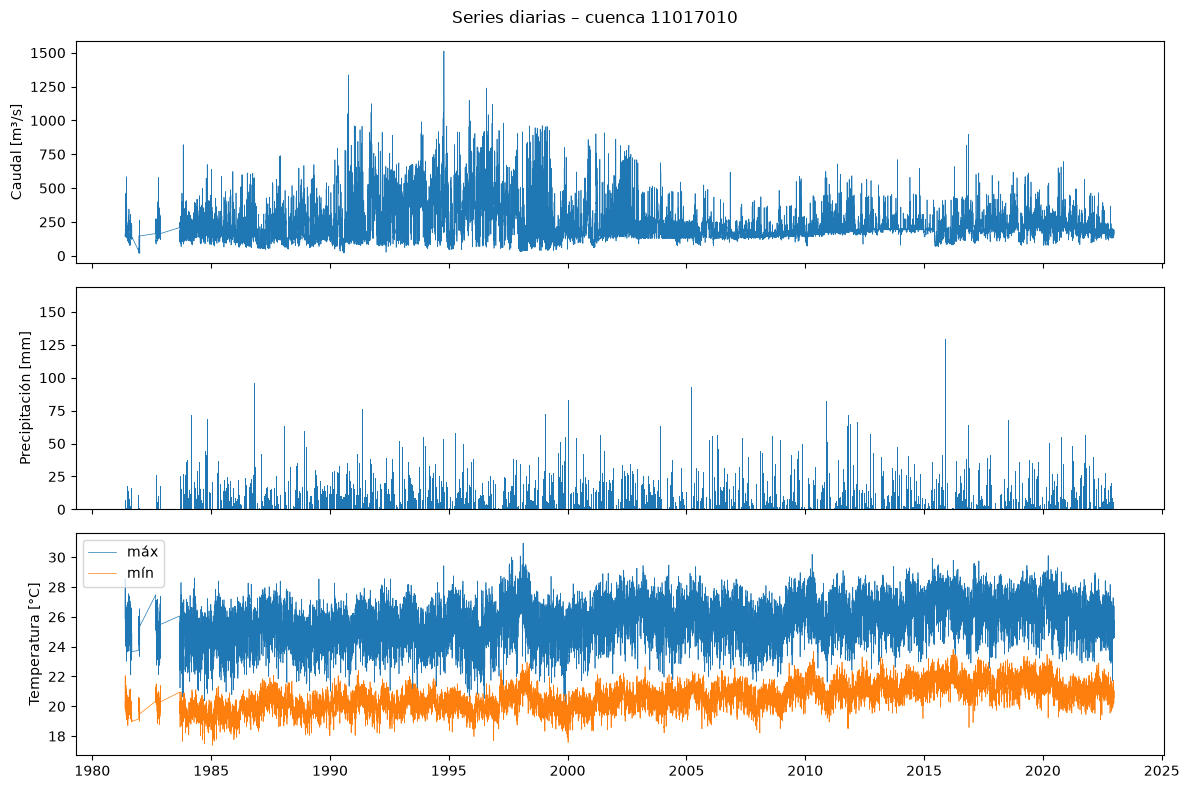

In [11]:
fig, ejes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
ejes[0].plot(ejemplo["Fecha"], ejemplo["Caudal"], lw=0.5)
ejes[0].set_ylabel("Caudal [m³/s]")
ejes[1].bar(ejemplo["Fecha"], ejemplo["Precipitacion"], width=1)
ejes[1].set_ylabel("Precipitación [mm]")
ejes[2].plot(ejemplo["Fecha"], ejemplo["Temperatura_maxima"], lw=0.5, label="máx")
ejes[2].plot(ejemplo["Fecha"], ejemplo["Temperatura_minima"], lw=0.5, label="mín")
ejes[2].set_ylabel("Temperatura [°C]")
ejes[2].legend()
fig.suptitle(f"Series diarias – cuenca {ejemplo_id}")
fig.tight_layout()
fig.savefig(SALIDAS / f"serie_ejemplo_{ejemplo_id}.png", dpi=120)
plt.show()

### 4a. Resumen de las 346 series
**Importante:** las series no tienen celdas vacías, pero eso engaña. Los datos faltantes aparecen como **días que directamente no están en el archivo**.
Por eso se cuentan los `dias_sin_registro` (huecos en las fechas). Esta celda tarda unos segundos.

In [12]:
filas = []
for ruta in sorted(SERIES_DIR.glob("Hydromet_data_*.txt")):
    gid = int(ruta.stem.split("_")[-1])
    s = cargar_serie(gid)
    dias_esperados = (s["Fecha"].max() - s["Fecha"].min()).days + 1
    filas.append({
        "gauge_id": gid,
        "inicio": s["Fecha"].min(),
        "fin": s["Fecha"].max(),
        "n_registros": len(s),
        "dias_sin_registro": dias_esperados - len(s),
        "pct_dias_faltantes": round((dias_esperados - len(s)) / dias_esperados * 100, 2),
        "celdas_vacias": int(s.isna().sum().sum()),
        "caudal_medio_m3s": round(s["Caudal"].mean(), 2),
    })

resumen_series = pd.DataFrame(filas)
resumen_series["anios"] = (resumen_series["n_registros"] / 365.25).round(1)
resumen_series.to_csv(SALIDAS / "resumen_series.csv", index=False)

print(f"Series: {len(resumen_series)}")
print(f"Series con huecos de fechas: {(resumen_series['dias_sin_registro'] > 0).sum()}")
print(f"Celdas vacías en total: {resumen_series['celdas_vacias'].sum()}")
resumen_series.describe().T

Series: 346
Series con huecos de fechas: 345
Celdas vacías en total: 0


,count,mean,min,25%,50%,75%,max,std
gauge_id,346.0,27934790.635838,11017010.0,21197015.0,24037035.0,35067080.0,54077030.0,11232600.830397
inicio,346,1983-07-18 23:26:42.312138,1981-01-01 00:00:00,1981-01-01 00:00:00,1981-01-01 00:00:00,1983-06-15 18:00:00,2008-11-04 00:00:00,NaN
fin,346,2017-12-12 09:26:00.693641,1992-07-17 00:00:00,2015-09-07 12:00:00,2021-11-24 12:00:00,2022-12-31 00:00:00,2022-12-31 00:00:00,NaN
n_registros,346.0,11771.294798,4151.0,9562.25,13103.5,14420.75,15308.0,3196.112973
dias_sin_registro,346.0,795.121387,0.0,316.5,675.5,1110.0,3020.0,625.719511
pct_dias_faltantes,346.0,6.361561,0.0,2.67,5.395,8.9575,19.91,4.675219
celdas_vacias,346.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
caudal_medio_m3s,346.0,305.649595,0.17,8.3275,28.31,167.4775,7393.78,834.062165
anios,346.0,32.226879,11.4,26.2,35.85,39.5,41.9,8.750891


## 5. Distribución de algunos atributos clave

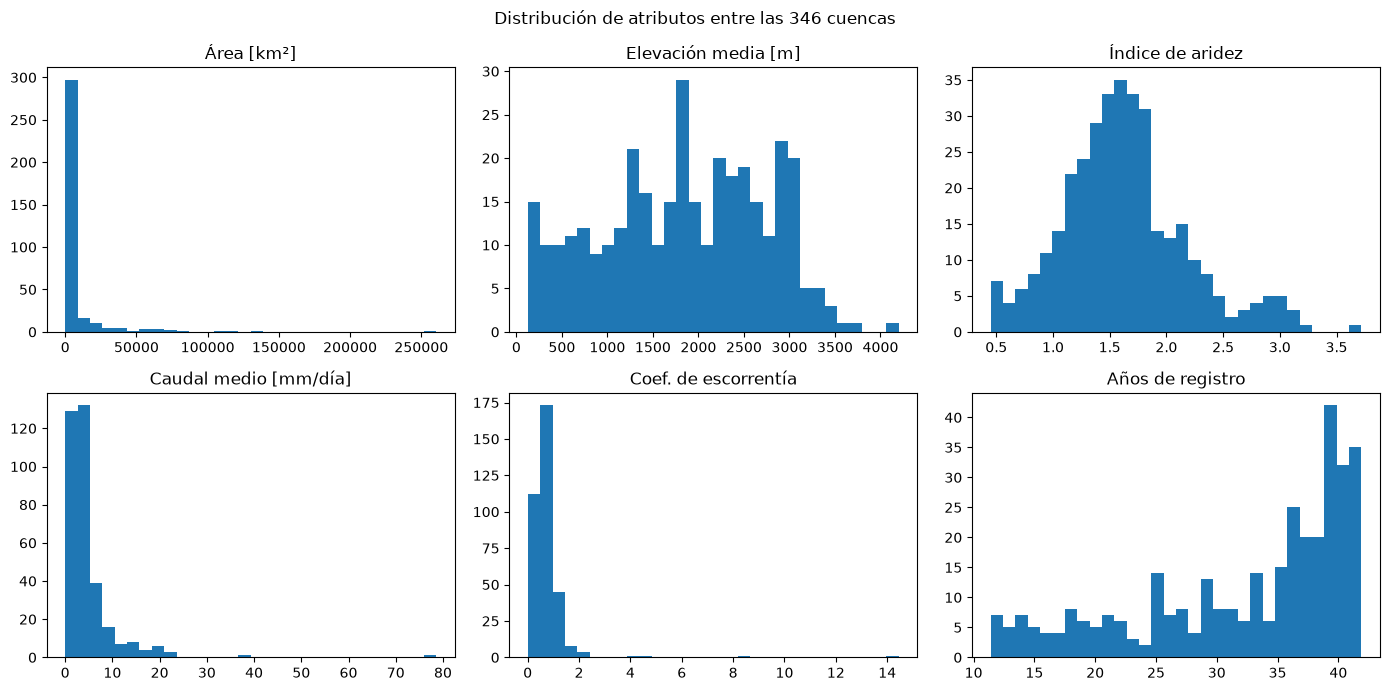

In [13]:
variables = [
    (tablas["fisiografia"], "area", "Área [km²]"),
    (tablas["fisiografia"], "mean_ele", "Elevación media [m]"),
    (tablas["clima"], "aridity", "Índice de aridez"),
    (tablas["firmas_hidro"], "q_mean", "Caudal medio [mm/día]"),
    (tablas["firmas_hidro"], "runoff_ratio", "Coef. de escorrentía"),
    (resumen_series, "anios", "Años de registro"),
]
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for eje, (df, col, etiqueta) in zip(ejes.flat, variables):
    eje.hist(df[col].dropna(), bins=30)
    eje.set_title(etiqueta)
fig.suptitle("Distribución de atributos entre las 346 cuencas")
fig.tight_layout()
fig.savefig(SALIDAS / "histogramas_atributos.png", dpi=120)
plt.show()

## 6. Qué nos dice esta exploración
- Las 8 tablas de atributos tienen las mismas 346 cuencas y **ningún nulo**.
- Las series tienen **días faltantes como filas ausentes**, no como celdas vacías. Antes de agregar por mes o calcular rezagos hay que reindexar a fechas continuas.
- Las escalas cambian muchísimo entre cuencas (el área va de ~25 a ~260 000 km²). Para comparar conviene usar escala log o variables normalizadas como `q_mean` (mm/día).
- Valores para revisar: `runoff_ratio` > 1 (sale más agua de la que llueve) y `high_q_dur` muy alto.
- Las estaciones se concentran en la región Andina, y la Amazonía y la Orinoquía están poco representadas.